In [1]:
!pip list


Package                   Version
------------------------- ----------
absl-py                   2.5.1
anyio                     4.15.1
argon2-cffi               25.1.0
argon2-cffi-bindings      26.1.0
arrow                     1.4.0
asttokens                 3.0.2
async-lru                 2.4.0
attrs                     26.1.0
babel                     2.18.0
beautifulsoup4            4.15.0
bleach                    6.4.0
certifi                   2026.10.23
cffi                      2.1.1
charset-normalizer        3.5.2
colorama                  0.4.6
comm                      0.2.3
contourpy                 1.4.0
cycler                    0.12.1
debugpy                   1.8.22
defusedxml                0.7.1
executing                 2.3.0
fastjsonschema            2.22.2
flatbuffers               25.12.19
fonttools                 4.68.0
fqdn                      1.6.0
h11                       0.16.0
httpcore                  1.0.9
httpx                     0.28.1
idna         


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import cv2
import numpy as np

# 1. Set the path to your Kaggle dataset folder
# Change 'alphabet_data' to whatever your Kaggle folder is actually named
dataset_path = 'Test' 

images = []
labels = []

# 2. Loop through every folder (A, B, C...)
for folder_name in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder_name)
    
    # Make sure it's actually a folder
    if os.path.isdir(folder_path):
        # 3. Loop through every image inside the folder
        for image_name in os.listdir(folder_path):
            image_path = os.path.join(folder_path, image_name)
            
            # Read the image using OpenCV
            img = cv2.imread(image_path)
            
            if img is not None:
                # Resize the image to 64x64 pixels (standard size for ML)
                img_resized = cv2.resize(img, (64, 64))
                
                # Save the image data and the letter label
                images.append(img_resized)
                labels.append(folder_name)

print(f"Successfully loaded {len(images)} images!")
print(f"Labels found: {set(labels)}")

Successfully loaded 112 images!
Labels found: {'M', 'O', 'R', 'C', 'N', 'T', 'L', 'F', 'W', 'P', 'S', 'U', 'G', 'Space', 'D', 'Nothing', 'V', 'J', 'X', 'I', 'K', 'H', 'Y', 'Z', 'B', 'E', 'A', 'Q'}


In [3]:
import mediapipe as mp
mp_hands = mp.solutions.hands
print("MediaPipe Hands is ready for landmark extraction.")

MediaPipe Hands is ready for landmark extraction.


In [ ]:
import os
import cv2
import mediapipe as mp
import numpy as np

# 1. Setup MediaPipe
mp_hands = mp.solutions.hands
# We use static_image_mode=True because we are processing images, not video
hands = mp_hands.Hands(static_image_mode=True, max_num_hands=1, min_detection_confidence=0.5)

dataset_path = 'Train' # Your Kaggle folder
data = []
labels = []

# 2. Loop through folders and images
for folder_name in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder_name)
    if os.path.isdir(folder_path):
        for image_name in os.listdir(folder_path):
            image_path = os.path.join(folder_path, image_name)
            img = cv2.imread(image_path)
            
            if img is not None:
                # Convert to RGB
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                
                # Process image to find hand
                results = hands.process(img_rgb)
                
                # If a hand is found
                if results.multi_hand_landmarks:
                    hand_landmarks = results.multi_hand_landmarks[0]
                    
                    # Extract x, y, z for all 21 landmarks
                    landmarks = []
                    for lm in hand_landmarks.landmark:
                        landmarks.extend([lm.x, lm.y, lm.z])
                    
                    data.append(landmarks)
                    labels.append(folder_name)

hands.close()
print(f"Finished extracting landmarks for {len(data)} images.")

In [4]:
import os
parent_folder = r"D:\Signverse\Notebooks\ASL_Dataset"

if os.path.exists(parent_folder):
    print("Found ASL_Dataset! Here is what is inside it:")
    print(os.listdir(parent_folder))
else:
    print("I cannot even find the ASL-Dataset folder. Check the path.")

Found ASL_Dataset! Here is what is inside it:
['Test', 'Train']


In [5]:
import os
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd # Added pandas for saving

mp_hands = mp.solutions.hands
hands = mp_hands.Hands(static_image_mode=True, max_num_hands=1, min_detection_confidence=0.5)

dataset_path = r"D:\Signverse\Notebooks\ASL_Dataset\Train" 

data = []
labels = []
image_paths = [] # NEW: List to store the file paths

IMAGES_PER_LETTER_LIMIT = 150 

for folder_name in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder_name)
    
    if os.path.isdir(folder_path):
        count = 0 
        
        for image_name in os.listdir(folder_path):
            if count >= IMAGES_PER_LETTER_LIMIT:
                break 
                
            image_path = os.path.join(folder_path, image_name)
            img = cv2.imread(image_path)
            
            if img is not None:
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                results = hands.process(img_rgb)
                
                if results.multi_hand_landmarks:
                    hand_landmarks = results.multi_hand_landmarks[0]
                    
                    landmarks = []
                    for lm in hand_landmarks.landmark:
                        landmarks.extend([lm.x, lm.y, lm.z])
                    
                    data.append(landmarks)
                    labels.append(folder_name)
                    image_paths.append(image_path) # NEW: Save the path
                    
                    count += 1 

hands.close()

# NEW: Save everything to a CSV so you can open it in Excel
df = pd.DataFrame(data)
df['Label'] = labels
df['Image_Path'] = image_paths
df.to_csv('hand_landmarks_data.csv', index=False)

print(f"Finished extracting landmarks for {len(data)} images.")
print("Saved to hand_landmarks_data.csv. You can open this file in Excel to see exactly which images were processed!")

D:\Datastets\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


Finished extracting landmarks for 4050 images.
Saved to hand_landmarks_data.csv. You can open this file in Excel to see exactly which images were processed!


Showing image for letter: A
File path: D:\Signverse\Notebooks\ASL_Dataset\Train\A\1008.jpg


D:\Datastets\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


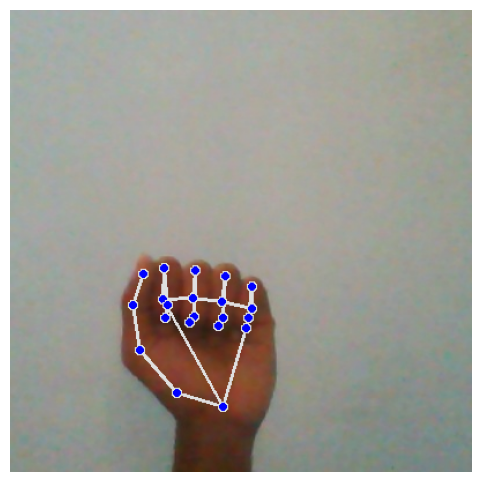

In [6]:
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp

# 1. Load the CSV we just created
df = pd.read_csv('hand_landmarks_data.csv')

# 2. Pick a random image from our processed data (let's say row 10)
sample_path = df.iloc[10]['Image_Path']
sample_label = df.iloc[10]['Label']

print(f"Showing image for letter: {sample_label}")
print(f"File path: {sample_path}")

# 3. Read the image
img = cv2.imread(sample_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 4. Draw the landmarks on it
mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils
hands = mp_hands.Hands(static_image_mode=True, max_num_hands=1)

results = hands.process(img_rgb)

if results.multi_hand_landmarks:
    for hand_landmarks in results.multi_hand_landmarks:
        mp_drawing.draw_landmarks(img_rgb, hand_landmarks, mp_hands.HAND_CONNECTIONS)

# 5. Display it right here in Jupyter
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.axis('off')
plt.show()

hands.close()